In [1]:
import pandas as pd
from sqlalchemy import create_engine, text

# Kết nối SQL Server
server_name = r'localhost\SQLEXPRESS' 
db_name = 'cicids2017_dw'
conn_str = f"mssql+pyodbc://@{server_name}/{db_name}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
engine = create_engine(conn_str)

print("🚀 BẮT ĐẦU CHẠY TRUY VẤN OLAP...")

with engine.connect() as conn:
    # ==============================================================
    # YÊU CẦU 1: TÍNH TRƯỚC 2 KHỐI CON (MATERIALIZED SUB-CUBES)
    # Bằng cách tạo VIEW trong SQL Server để lưu sẵn kết quả tổng hợp
    # ==============================================================
    
    # Khối 1: Tổng hợp lưu lượng mạng theo Giờ và Giao thức
    # Lý do: Giúp Dashboard giám sát băng thông load dữ liệu cực nhanh mà không cần quét bảng Fact.
    conn.execute(text("""
        CREATE OR ALTER VIEW vw_cube_traffic_hourly AS
        SELECT t.date_value, t.hour_num, p.protocol_name,
               SUM(f.total_length_of_fwd_packets + f.total_length_of_bwd_packets) as total_bytes,
               COUNT(f.flow_key) as flow_count
        FROM fact_flow f
        JOIN dim_time t ON f.time_key = t.time_key
        JOIN dim_protocol p ON f.protocol_key = p.protocol_key
        GROUP BY t.date_value, t.hour_num, p.protocol_name;
    """))
    
    # Khối 2: Đếm số lượng tấn công theo IP Nguồn
    # Lý do: Phục vụ riêng cho bộ phận An ninh mạng theo dõi các "Blacklist IP" hoạt động mạnh nhất.
    conn.execute(text("""
        CREATE OR ALTER VIEW vw_cube_attack_source AS
        SELECT i.ip_address, l.attack_group, COUNT(f.flow_key) as attack_count
        FROM fact_flow f
        JOIN dim_ip i ON f.src_ip_key = i.ip_key
        JOIN dim_label l ON f.label_key = l.label_key
        WHERE l.is_attack = 1
        GROUP BY i.ip_address, l.attack_group;
    """))
    conn.commit()
    print("✅ Đã tạo xong 2 Khối con (Views) trong SQL Server.\n")

    # ==============================================================
    # YÊU CẦU 2: THỰC THI 5 THAO TÁC OLAP CƠ BẢN
    # ==============================================================
    
    # 1. SLICE (Cắt lát) - Cố định 1 chiều: Chỉ xem số liệu của luồng tấn công DDoS
    print("🔪 1. SLICE: Lưu lượng tấn công DDoS theo từng ngày")
    df_slice = pd.read_sql(text("""
        SELECT t.date_value, COUNT(f.flow_key) as ddos_flows
        FROM fact_flow f
        JOIN dim_label l ON f.label_key = l.label_key
        JOIN dim_time t ON f.time_key = t.time_key
        WHERE l.attack_group = 'DDoS'
        GROUP BY t.date_value;
    """), conn)
    display(df_slice)

    # 2. DICE (Cắt khối) - Lọc trên nhiều chiều: Xem giao thức TCP bị PortScan trong Giờ hành chính
    print("\n🎲 2. DICE: Tấn công PortScan trên giao thức TCP trong Giờ hành chính")
    df_dice = pd.read_sql(text("""
        SELECT t.hour_num, p.protocol_name, COUNT(f.flow_key) as incident_count
        FROM fact_flow f
        JOIN dim_time t ON f.time_key = t.time_key
        JOIN dim_protocol p ON f.protocol_key = p.protocol_key
        JOIN dim_label l ON f.label_key = l.label_key
        WHERE p.protocol_name = 'TCP' 
          AND l.attack_group = 'PortScan'
          AND t.is_business_hours = 1
        GROUP BY t.hour_num, p.protocol_name;
    """), conn)
    display(df_dice.head())

    # 3. ROLL-UP (Cuộn lên) - Đi lên một mức phân cấp: Từ Giờ cuộn lên tổng Ngày
    print("\n⬆️ 3. ROLL-UP: Tổng băng thông theo Ngày (tổng hợp từ khối con theo Giờ)")
    df_rollup = pd.read_sql(text("""
        SELECT date_value, protocol_name, SUM(total_bytes) as daily_total_bytes
        FROM vw_cube_traffic_hourly
        GROUP BY date_value, protocol_name;
    """), conn)
    display(df_rollup.head())

    # 4. DRILL-DOWN (Khoan xuống) - Đi sâu chi tiết: Từ Ngày khoan xuống phân bố theo từng Giờ
    print("\n⬇️ 4. DRILL-DOWN: Bóc tách đợt tấn công DDoS trong ngày xuống chi tiết từng giờ")
    df_drilldown = pd.read_sql(text("""
        SELECT t.date_value, t.hour_num, COUNT(f.flow_key) as ddos_flows
        FROM fact_flow f
        JOIN dim_label l ON f.label_key = l.label_key
        JOIN dim_time t ON f.time_key = t.time_key
        WHERE l.attack_group = 'DDoS'
        GROUP BY t.date_value, t.hour_num
        ORDER BY t.date_value, t.hour_num;
    """), conn)
    display(df_drilldown.head(10))

    # 5. PIVOT (Xoay trục) - Chuyển Hàng thành Cột: Phân bố nhóm tấn công theo Giao thức (TCP, UDP)
    print("\n🔄 5. PIVOT: Bảng chéo giữa Nhóm tấn công (Hàng) và Giao thức mạng (Cột)")
    df_pivot = pd.read_sql(text("""
        SELECT *
        FROM (
            SELECT p.protocol_name, l.attack_group, f.flow_key
            FROM fact_flow f
            JOIN dim_protocol p ON f.protocol_key = p.protocol_key
            JOIN dim_label l ON f.label_key = l.label_key
            WHERE l.is_attack = 1
        ) AS SourceTable
        PIVOT (
            COUNT(flow_key)
            FOR protocol_name IN ([TCP], [UDP])
        ) AS PivotTable;
    """), conn)
    display(df_pivot)

🚀 BẮT ĐẦU CHẠY TRUY VẤN OLAP...
✅ Đã tạo xong 2 Khối con (Views) trong SQL Server.

🔪 1. SLICE: Lưu lượng tấn công DDoS theo từng ngày


,date_value,ddos_flows
0,2017-07-06,2216
1,2017-07-04,13832
2,2017-07-07,288785
3,2017-07-05,251722



🎲 2. DICE: Tấn công PortScan trên giao thức TCP trong Giờ hành chính


,hour_num,protocol_name,incident_count



⬆️ 3. ROLL-UP: Tổng băng thông theo Ngày (tổng hợp từ khối con theo Giờ)


,date_value,protocol_name,daily_total_bytes
0,2017-07-03,HOPOPT/IPv6,0
1,2017-07-04,HOPOPT/IPv6,0
2,2017-07-05,HOPOPT/IPv6,0
3,2017-07-06,HOPOPT/IPv6,0
4,2017-07-07,HOPOPT/IPv6,0



⬇️ 4. DRILL-DOWN: Bóc tách đợt tấn công DDoS trong ngày xuống chi tiết từng giờ


,date_value,hour_num,ddos_flows
0,2017-07-04,9,5264
1,2017-07-04,10,2671
2,2017-07-04,14,4899
3,2017-07-04,15,998
4,2017-07-05,9,3201
5,2017-07-05,10,228503
6,2017-07-05,11,20002
7,2017-07-05,14,5
8,2017-07-05,15,11
9,2017-07-06,9,1500



🔄 5. PIVOT: Bảng chéo giữa Nhóm tấn công (Hàng) và Giao thức mạng (Cột)


,attack_group,TCP,UDP
0,DDoS,556548,1


In [1]:
# ==============================================================================
# NOTEBOOK 03: TRUY VẤN PHÂN TÍCH ĐA CHIỀU (OLAP) & TRỰC QUAN HÓA
# ==============================================================================
import os
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn và style biểu đồ
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
sys.path.append(os.getcwd())

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Nạp kết nối từ cấu hình chuẩn
from src.utils.config import get_connection

print("⏳ Đang kết nối tới kho dữ liệu PostgreSQL 'cicids2017_dw'...")
conn = get_connection()
print("✅ Kết nối thành công! Sẵn sàng thực hiện các truy vấn OLAP.")


⏳ Đang kết nối tới kho dữ liệu PostgreSQL 'cicids2017_dw'...
✅ Kết nối thành công! Sẵn sàng thực hiện các truy vấn OLAP.


C:\Users\Admin\AppData\Local\Temp\ipykernel_27736\887030364.py:13: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_slice = pd.read_sql(query_slice, conn)


📊 KẾT QUẢ SLICE: Tỷ lệ các nhóm tấn công mạng


,attack_group,total_flows
0,Other,266541
1,PortScan,158930
2,DDoS,128027
3,WebAttack,2180
4,Botnet,1966


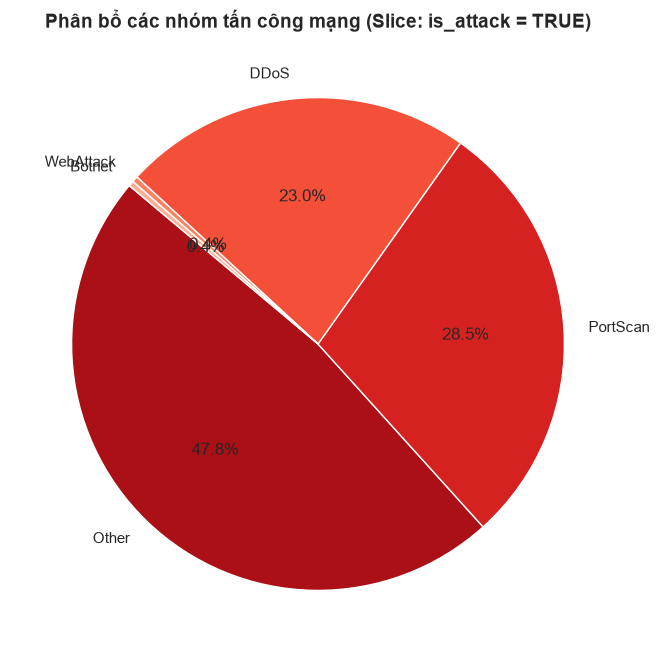

In [2]:
# 🔪 THAO TÁC SLICE: Lọc riêng các luồng mạng là tấn công và xem tỷ lệ các nhóm
query_slice = """
    SELECT 
        l.attack_group, 
        COUNT(f.flow_key) as total_flows
    FROM fact_flow f
    JOIN dim_label l ON f.label_key = l.label_key
    WHERE l.is_attack = TRUE
    GROUP BY l.attack_group
    ORDER BY total_flows DESC;
"""

df_slice = pd.read_sql(query_slice, conn)

print("📊 KẾT QUẢ SLICE: Tỷ lệ các nhóm tấn công mạng")
display(df_slice)

# Vẽ biểu đồ Tròn
plt.figure(figsize=(8, 8))
plt.pie(df_slice['total_flows'], labels=df_slice['attack_group'], autopct='%1.1f%%', startangle=140, colors=sns.color_palette("Reds_r"))
plt.title("Phân bổ các nhóm tấn công mạng (Slice: is_attack = TRUE)", fontsize=14, fontweight='bold')
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_27736\381148152.py:17: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_dice = pd.read_sql(query_dice, conn)


📊 KẾT QUẢ DICE: Tần suất DDoS vào cổng 80 theo giờ làm việc


,hour_num,attack_count
0,15,23865
1,16,104159


C:\Users\Admin\AppData\Local\Temp\ipykernel_27736\381148152.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='hour_num', y='attack_count', data=df_dice, palette="viridis")


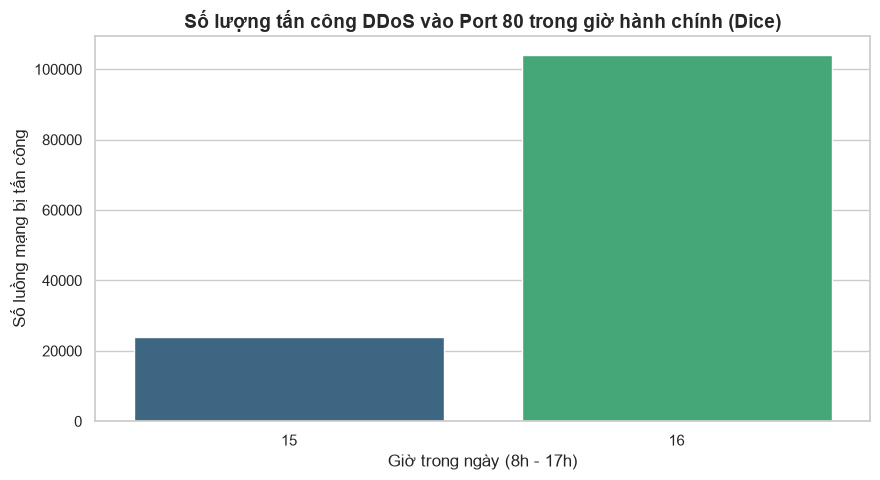

In [3]:
# 🎲 THAO TÁC DICE: Phân tích tấn công DDoS nhắm vào Web (Port 80) trong giờ hành chính
query_dice = """
    SELECT 
        t.hour_num, 
        COUNT(f.flow_key) as attack_count
    FROM fact_flow f
    JOIN dim_label l ON f.label_key = l.label_key
    JOIN dim_port p ON f.dst_port_key = p.port_key
    JOIN dim_time t ON f.time_key = t.time_key
    WHERE l.attack_group = 'DDoS' 
      AND p.port_number = 80 
      AND t.is_business_hours = TRUE
    GROUP BY t.hour_num
    ORDER BY t.hour_num;
"""

df_dice = pd.read_sql(query_dice, conn)

print("📊 KẾT QUẢ DICE: Tần suất DDoS vào cổng 80 theo giờ làm việc")
display(df_dice)

# Vẽ biểu đồ Cột
plt.figure(figsize=(10, 5))
sns.barplot(x='hour_num', y='attack_count', data=df_dice, palette="viridis")
plt.title("Số lượng tấn công DDoS vào Port 80 trong giờ hành chính (Dice)", fontsize=14, fontweight='bold')
plt.xlabel("Giờ trong ngày (8h - 17h)")
plt.ylabel("Số luồng mạng bị tấn công")
plt.show()

C:\Users\Admin\AppData\Local\Temp\ipykernel_27736\4128659949.py:12: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_rollup = pd.read_sql(query_rollup, conn)


📊 KẾT QUẢ ROLL-UP: Tổng dung lượng mạng tiêu thụ (GB) theo ngày


,day_name,total_gb
0,Wednesday,11.323022
1,Tuesday,9.299666
2,Monday,9.096065
3,Friday,7.392123
4,Thursday,6.947406


C:\Users\Admin\AppData\Local\Temp\ipykernel_27736\4128659949.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='day_name', y='total_gb', data=df_rollup, palette="Blues_d")


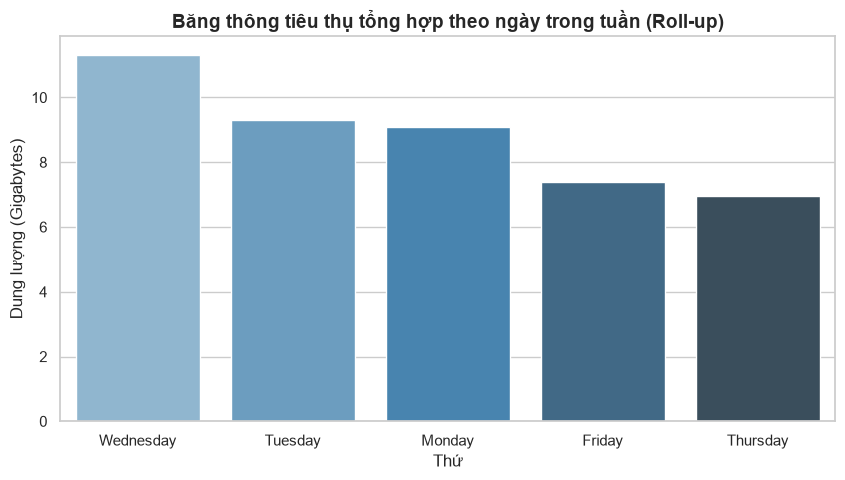

In [4]:
# ⬆️ THAO TÁC ROLL-UP: Tổng hợp băng thông mạng theo từng ngày trong tuần
query_rollup = """
    SELECT 
        t.day_name, 
        SUM(f.total_bytes) / (1024*1024*1024.0) as total_gb
    FROM fact_flow f
    JOIN dim_time t ON f.time_key = t.time_key
    GROUP BY t.day_name
    ORDER BY total_gb DESC;
"""

df_rollup = pd.read_sql(query_rollup, conn)

print("📊 KẾT QUẢ ROLL-UP: Tổng dung lượng mạng tiêu thụ (GB) theo ngày")
display(df_rollup)

# Vẽ biểu đồ
plt.figure(figsize=(10, 5))
sns.barplot(x='day_name', y='total_gb', data=df_rollup, palette="Blues_d")
plt.title("Băng thông tiêu thụ tổng hợp theo ngày trong tuần (Roll-up)", fontsize=14, fontweight='bold')
plt.xlabel("Thứ")
plt.ylabel("Dung lượng (Gigabytes)")
plt.show()

In [5]:
# ⬇️ THAO TÁC DRILL-DOWN: Truy vết Top 5 IP nguồn thực hiện WebAttack nhiều nhất
query_drilldown = """
    SELECT 
        i.ip_address, 
        i.is_blacklisted,
        COUNT(f.flow_key) as attack_attempts
    FROM fact_flow f
    JOIN dim_label l ON f.label_key = l.label_key
    JOIN dim_ip i ON f.src_ip_key = i.ip_key
    WHERE l.attack_group = 'WebAttack'
    GROUP BY i.ip_address, i.is_blacklisted
    ORDER BY attack_attempts DESC
    LIMIT 5;
"""

df_drilldown = pd.read_sql(query_drilldown, conn)

print("📊 KẾT QUẢ DRILL-DOWN: Top 5 IP tội phạm thực hiện tấn công Web")
display(df_drilldown)

# Đóng kết nối DB khi hoàn thành
conn.close()
print("\n✅ Đã đóng kết nối cơ sở dữ liệu.")

C:\Users\Admin\AppData\Local\Temp\ipykernel_27736\221649482.py:16: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_drilldown = pd.read_sql(query_drilldown, conn)


📊 KẾT QUẢ DRILL-DOWN: Top 5 IP tội phạm thực hiện tấn công Web


,ip_address,is_blacklisted,attack_attempts
0,172.16.0.1,False,2180



✅ Đã đóng kết nối cơ sở dữ liệu.


In [1]:
# Cell 1: Khởi tạo
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import os

if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
csv_dir = Path("reports/tables")

# Cell 2: Thao tác ROLL-UP (Băng thông theo giao thức & Khung giờ)
file_path = csv_dir / "q3_protocol_by_hour.csv"
if file_path.exists():
    df_q3 = pd.read_csv(file_path)
    print("📊 ROLL-UP: BĂNG THÔNG TIÊU THỤ THEO GIỜ VÀ GIAO THỨC")
    display(df_q3.head(10))
    plt.figure(figsize=(12, 6))
    sns.lineplot(data=df_q3, x='hour_num', y='mb_consumed', hue='protocol_name', marker='o')
    plt.title("Băng thông tiêu thụ (MB) theo giờ trong ngày", fontweight='bold')
    plt.xticks(range(8, 18))
    plt.show()

# Cell 3: Thao tác DRILL-DOWN (Top IP PortScan)
file_path = csv_dir / "q4_portscan_sources.csv"
if file_path.exists():
    df_q4 = pd.read_csv(file_path)
    print("🎯 DRILL-DOWN: TOP 10 ĐỊA CHỈ IP QUÉT CỔNG (PORTSCAN)")
    top_10 = df_q4.head(10)
    plt.figure(figsize=(10, 6))
    sns.barplot(data=top_10, x='so_flow_portscan', y='ip_address', palette='Reds_r')
    plt.title("Top 10 IP thực hiện PortScan", fontweight='bold')
    plt.show()

# Cell 4: Thao tác CUBE (Phân bố tấn công theo Dịch vụ mạng)
file_path = csv_dir / "olap_cube_attack_service.csv"
if file_path.exists():
    df_cube = pd.read_csv(file_path).dropna()
    df_attack = df_cube[df_cube['attack_group'] != 'Benign'].sort_values(by='so_flow', ascending=False).head(15)
    print("🎲 CUBE: PHÂN BỐ TẤN CÔNG THEO DỊCH VỤ CỔNG ĐÍCH")
    plt.figure(figsize=(12, 7))
    sns.barplot(data=df_attack, x='so_flow', y='attack_group', hue='service_name', dodge=True, palette='tab10')
    plt.title("Phân bố nhóm tấn công nhắm vào các dịch vụ mạng", fontweight='bold')
    plt.legend(title='Dịch vụ mạng đích')
    plt.show()

# Cell 5: Thao tác PIVOT (Tấn công theo Thứ trong tuần)
file_path = csv_dir / "olap_pivot_attack_by_day.csv"
if file_path.exists():
    df_pivot = pd.read_csv(file_path)
    print("🔄 PIVOT: TẦN SUẤT TẤN CÔNG THEO NGÀY TRONG TUẦN")
    display(df_pivot)